# Classifier benchmark – healthy vs. unhealthy (Rafaela)

**Question.** Which classifier from the course best decodes, from the EEG while the image is on screen, whether the participant judges the food **healthy** or **unhealthy**?

**Setup.** 6 development subjects (sub-006, 008, 009, 013, 014, 015), 360 image-locked trials per subject: the answer to "Healthy?" is copied to the 3 presentations of each image (`load_subject` from `outils.py`). Cross-validation is always grouped by image, so the same food is never in both the training and the test set.

**Main findings.**
- None of the 8 classifiers decodes healthy vs. unhealthy above chance on average (mean AUC 0.49–0.52); differences between classifiers are much smaller than differences between subjects.
- Adding a PCA step does not help (all 8 PCA versions between 0.48 and 0.50).
- sub-006 shows a genuine effect between ≈ 200 and 580 ms (AUC up to 0.66, above all shuffled-label curves), but not the other subjects → more subjects are needed.
- **Choice for the next steps: LDA with shrinkage, without PCA** (among the best, fastest, no hyperparameter to tune).

**Outline**
1. Setup
2. Data for one subject
3. Models and nested cross-validation
4. Benchmark of 8 classifiers (window 200–500 ms)
5. Same classifiers with PCA
6. Time-resolved decoding with LDA
7. Chance-level control (sub-006)
8. Conclusion

## 1. Setup

In [ ]:
import time
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import LinearSVC, SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.exceptions import ConvergenceWarning

from outils import load_subject, decode_time, chance_control, plot_curves

warnings.filterwarnings("ignore", category=ConvergenceWarning)   # MLP / saga iteration warnings

SUBJECTS = ["sub-006", "sub-008", "sub-009", "sub-013", "sub-014", "sub-015"]

## 2. Data for one subject

`load_subject` returns X (epoch × channel × time_ms, −100 to 1000 ms after image onset), y (1 = healthy, 0 = unhealthy) and the image code of each trial (used as groups). For the benchmark, each trial is summarised by the mean activity of each electrode between 200 and 500 ms (the window where the paper finds a difference) → X_window of shape (360, 64).

In [8]:
X, y, images = load_subject('sub-006')

print("X shape:", X.shape)
print("y sum:", y.sum())
print('X dims :', X.dims)



X shape: (360, 64, 282)
y sum: 174
X dims : ('epoch', 'channel', 'time_ms')


In [10]:
X_200_500 = X.sel(time_ms=slice(200, 500))  # EEG between 200 and 500 ms
X_200_500_mean = X_200_500.mean(dim='time_ms')  # mean over that window
X_window = X_200_500_mean.values

print("X_window shape:", X_window.shape)

X_window shape: (360, 64)


## 3. Models and nested cross-validation

8 classifiers from the course, each in a pipeline with `StandardScaler`, with a small grid of hyperparameters.

**Nested cross-validation** (`nested_cv`): an outer 5-fold `StratifiedGroupKFold` (groups = images) gives the score; inside each outer fold, `GridSearchCV` (another 5-fold `StratifiedGroupKFold`) picks the hyperparameters using the training trials only. The score is the AUC on the outer test fold (`clf.score` uses `decision_function` or `predict_proba` as needed).

In [14]:
models = {
    "LogReg L2": (
        make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
        {"logisticregression__C": [0.001, 0.01, 0.1, 1, 10]},
    ),
    "LogReg L1": (
        make_pipeline(StandardScaler(), LogisticRegression(penalty="l1", solver="liblinear", max_iter=1000)),
        {"logisticregression__C": [0.01, 0.1, 1, 10]},
    ),
    "LogReg ElasticNet": (
        make_pipeline(StandardScaler(), LogisticRegression(penalty="elasticnet", solver="saga", max_iter=5000)),
        {"logisticregression__C": [0.01, 0.1, 1],
         "logisticregression__l1_ratio": [0.2, 0.5, 0.8]},
    ),
    "LDA shrinkage": (
        make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(solver="lsqr")),
        {"lineardiscriminantanalysis__shrinkage": ["auto"]},
    ),
    "SVM Linear": (
        make_pipeline(StandardScaler(), LinearSVC(max_iter=5000)),
        {"linearsvc__C": [0.001, 0.01, 0.1, 1]},
    ),
    "SVM RBF": (
        make_pipeline(StandardScaler(), SVC(kernel="rbf")),
        {"svc__C": [0.1, 1, 10],
         "svc__gamma": ["scale", 0.001, 0.01]},
    ),
    "KNN": (
        make_pipeline(StandardScaler(), KNeighborsClassifier()),
        {"kneighborsclassifier__n_neighbors": [5, 15, 31, 51],
         "kneighborsclassifier__weights": ["uniform", "distance"]},
    ),
    "MLP": (
        make_pipeline(StandardScaler(), MLPClassifier(max_iter=1000, random_state=0, early_stopping=True)),
        {"mlpclassifier__hidden_layer_sizes": [(16,), (64,)],
         "mlpclassifier__alpha": [0.001, 0.1, 1]},
    ),
}

print(len(models), "models:", list(models))

8 models: ['LogReg L2', 'LogReg L1', 'LogReg ElasticNet', 'LDA shrinkage', 'SVM Linear', 'SVM RBF', 'KNN', 'MLP']


In [23]:
def nested_cv(pipeline, grid, X, y, groups):
    outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)
    inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=1)
    AUC = []
    chosen_params = []

    for train_idx, test_idx in outer.split(X, y, groups):
        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]
        groups_train = groups[train_idx]

        clf = GridSearchCV(pipeline, grid, scoring="roc_auc", cv=inner)
        clf.fit(X_train, y_train, groups=groups_train)

        chosen_params.append(clf.best_params_)
        AUC.append(clf.score(X_test, y_test))   # AUC on the test trials

    return np.mean(AUC), chosen_params

Test on sub-006 with logistic regression (L2):

In [19]:
pipe, grid = models["LogReg L2"]
nested_cv(pipe, grid, X_window, y, images)


(np.float64(0.6459910357132579),
 [{'logisticregression__C': 0.01},
  {'logisticregression__C': 0.1},
  {'logisticregression__C': 0.01},
  {'logisticregression__C': 0.1},
  {'logisticregression__C': 0.01}])

## 4. Benchmark of 8 classifiers (window 200–500 ms)

In [24]:
results = []                                   # all results are stored here

for sub in SUBJECTS:
    print("Processing subject:", sub)
    X, y, images = load_subject(sub)
    X_200_500 = X.sel(time_ms=slice(200, 500))
    X_200_500_mean = X_200_500.mean(dim="time_ms")
    X_window = X_200_500_mean.values

    for mod_name, (pipe, grid) in models.items():
        t0 = time.time()
        mean_auc, chosen_params = nested_cv(pipe, grid, X_window, y, images)
        duration = time.time() - t0

        results.append({
            "subject": sub,
            "model": mod_name,
            "auc": mean_auc,
            "params": chosen_params,
            "time_s": duration,
        })
        print(f"  {mod_name:<18} AUC = {mean_auc:.3f}   ({duration:.1f} s)")

df = pd.DataFrame(results)
df.groupby("model")["auc"].mean().sort_values(ascending=False)

Processing subject: sub-006
  LogReg L2          AUC = 0.646   (2.6 s)
  LogReg L1          AUC = 0.634   (1.8 s)
  LogReg ElasticNet  AUC = 0.649   (8.3 s)
  LDA shrinkage      AUC = 0.649   (0.5 s)
  SVM Linear         AUC = 0.647   (1.0 s)
  SVM RBF            AUC = 0.624   (2.4 s)
  KNN                AUC = 0.573   (1.5 s)
  MLP                AUC = 0.588   (112.6 s)
Processing subject: sub-008
  LogReg L2          AUC = 0.456   (1.6 s)
  LogReg L1          AUC = 0.467   (1.7 s)
  LogReg ElasticNet  AUC = 0.461   (9.9 s)
  LDA shrinkage      AUC = 0.455   (0.5 s)
  SVM Linear         AUC = 0.431   (0.8 s)
  SVM RBF            AUC = 0.465   (2.1 s)
  KNN                AUC = 0.460   (1.8 s)
  MLP                AUC = 0.470   (113.4 s)
Processing subject: sub-009
  LogReg L2          AUC = 0.439   (2.1 s)
  LogReg L1          AUC = 0.478   (2.8 s)
  LogReg ElasticNet  AUC = 0.470   (12.5 s)
  LDA shrinkage      AUC = 0.458   (0.5 s)
  SVM Linear         AUC = 0.435   (0.9 s)
  SVM RB

model
SVM RBF              0.521797
LDA shrinkage        0.515814
MLP                  0.513175
LogReg L2            0.507346
SVM Linear           0.499568
LogReg L1            0.498769
LogReg ElasticNet    0.498197
KNN                  0.492372
Name: auc, dtype: float64

In [25]:
# Table: subjects × models
auc_table = df.pivot(index="subject", columns="model", values="auc")
display(auc_table.round(3))

# Summary per model: mean, standard deviation, number of subjects above 0.5
summary = df.groupby("model")["auc"].agg(
    mean="mean",
    std="std",
    n_above_chance=lambda a: (a > 0.5).sum(),
).sort_values("mean", ascending=False)

# Most often chosen hyperparameters per model (over all folds and subjects)
def most_common_params(params_lists):
    all_params = [tuple(sorted(p.items())) for plist in params_lists for p in plist]
    best, count = Counter(all_params).most_common(1)[0]
    return f"{dict(best)} ({count}/{len(all_params)})"

summary["most_chosen_params"] = df.groupby("model")["params"].apply(most_common_params)
display(summary.round(3))

model,KNN,LDA shrinkage,LogReg ElasticNet,LogReg L1,LogReg L2,MLP,SVM Linear,SVM RBF
subject,,,,,,,,
sub-006,0.573,0.649,0.649,0.634,0.646,0.588,0.647,0.624
sub-008,0.460,0.455,0.461,0.467,0.456,0.470,0.431,0.465
sub-009,0.415,0.458,0.470,0.478,0.439,0.455,0.435,0.410
sub-013,0.511,0.562,0.507,0.495,0.540,0.508,0.541,0.535
sub-014,0.427,0.458,0.429,0.440,0.454,0.526,0.433,0.484
sub-015,0.568,0.514,0.475,0.479,0.510,0.531,0.512,0.614


,mean,std,n_above_chance,most_chosen_params
model,,,,
SVM RBF,0.522,0.085,3,"{'svc__C': 0.1, 'svc__gamma': 0.01} (6/30)"
LDA shrinkage,0.516,0.078,3,{'lineardiscriminantanalysis__shrinkage': 'aut...
MLP,0.513,0.048,4,"{'mlpclassifier__alpha': 1, 'mlpclassifier__hi..."
LogReg L2,0.507,0.078,3,{'logisticregression__C': 0.001} (9/30)
SVM Linear,0.500,0.086,3,{'linearsvc__C': 0.001} (10/30)
LogReg L1,0.499,0.069,1,{'logisticregression__C': 0.1} (10/30)
LogReg ElasticNet,0.498,0.078,2,"{'logisticregression__C': 0.01, 'logisticregre..."
KNN,0.492,0.069,3,"{'kneighborsclassifier__n_neighbors': 15, 'kne..."


In [26]:
df_to_save = df.copy()
df_to_save["params"] = df_to_save["params"].astype(str)   # dictionaries as text for the CSV

df_to_save.to_csv("benchmark_healthy_6subjects_detail.csv", index=False)
summary.to_csv("benchmark_healthy_6subjects_summary.csv")
print("Saved.")

Saved.


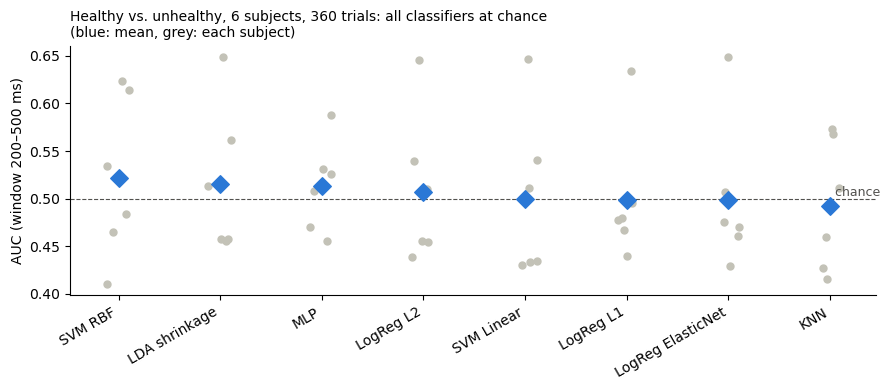

In [27]:
order = summary.index                                   # models from best to worst
x = np.arange(len(order))

fig, ax = plt.subplots(figsize=(9, 4))
rng = np.random.default_rng(0)
for i, model in enumerate(order):
    values = auc_table[model].values
    jitter = rng.uniform(-0.12, 0.12, size=len(values))
    ax.scatter(i + jitter, values, color="#c3c2b7", s=25, zorder=2)              # each subject
ax.scatter(x, summary["mean"], color="#2a78d6", s=80, marker="D", zorder=3)     # mean
ax.axhline(0.5, color="#52514e", linewidth=0.8, linestyle="--")
ax.text(len(order) - 0.5, 0.5, " chance", va="bottom", ha="right", color="#52514e", fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(order, rotation=30, ha="right")
ax.set_ylabel("AUC (window 200–500 ms)")
ax.set_title("Healthy vs. unhealthy, 6 subjects, 360 trials: all classifiers at chance\n"
             "(blue: mean, grey: each subject)", loc="left", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("benchmark_healthy_6subjects.png", dpi=200)
plt.show()

**Results (20 Nov)** – AUC per subject, window 200–500 ms, 360 trials, nested cross-validation grouped by image.

| Model | sub-006 | sub-008 | sub-009 | sub-013 | sub-014 | sub-015 | **Mean** |
|---|---|---|---|---|---|---|---|
| SVM RBF | 0.624 | 0.465 | 0.410 | 0.535 | 0.484 | 0.614 | **0.522** |
| LDA shrinkage | 0.649 | 0.455 | 0.458 | 0.562 | 0.458 | 0.514 | **0.516** |
| MLP | 0.588 | 0.470 | 0.455 | 0.508 | 0.526 | 0.531 | **0.513** |
| LogReg L2 | 0.646 | 0.456 | 0.439 | 0.540 | 0.454 | 0.510 | **0.507** |
| SVM Linear | 0.647 | 0.431 | 0.435 | 0.541 | 0.433 | 0.512 | **0.500** |
| LogReg L1 | 0.634 | 0.467 | 0.478 | 0.495 | 0.440 | 0.479 | **0.499** |
| LogReg ElasticNet | 0.649 | 0.461 | 0.470 | 0.507 | 0.429 | 0.475 | **0.498** |
| KNN | 0.573 | 0.460 | 0.415 | 0.511 | 0.427 | 0.568 | **0.492** |

**Interpretation**
- All means are between 0.49 and 0.52: **no classifier decodes above chance** on average. The ranking is not meaningful: the gap between the first and the last model (0.03) is much smaller than the spread between subjects (0.41 to 0.65).
- **The subject matters more than the method**: sub-006 is at ≈ 0.63–0.65 with every linear model, sub-008, 009 and 014 are below 0.5 with almost every model.
- Linear models choose strong regularisation (e.g. C = 0.01–0.1 for logistic regression on sub-006): with few trials and much noise, simpler models are preferred (bias–variance trade-off).
- Non-linear models (SVM RBF, KNN, MLP) do not do better; the MLP is ≈ 200 times slower than the LDA.

## 5. Same classifiers with PCA

A PCA step is added **inside** the pipeline (fitted on the training trials of each fold only, so no information leaks from the test set). The number of components (5, 10, 20, 40) is tuned by the inner `GridSearchCV`.

In [31]:
# ---------- The 8 classifiers with PCA ----------
pca_grid = [5, 10, 20, 40]

models_pca = {
    "LogReg L2 + PCA": (
        make_pipeline(StandardScaler(), PCA(), LogisticRegression(max_iter=1000)),
        {"pca__n_components": pca_grid, "logisticregression__C": [0.01, 0.1, 1]},
    ),
    "LogReg L1 + PCA": (
        make_pipeline(StandardScaler(), PCA(), LogisticRegression(penalty="l1", solver="liblinear", max_iter=1000)),
        {"pca__n_components": pca_grid, "logisticregression__C": [0.01, 0.1, 1]},
    ),
    "LogReg ElasticNet + PCA": (
        make_pipeline(StandardScaler(), PCA(), LogisticRegression(penalty="elasticnet", solver="saga", max_iter=5000)),
        {"pca__n_components": pca_grid, "logisticregression__C": [0.01, 0.1, 1],
         "logisticregression__l1_ratio": [0.5]},
    ),
    "LDA shrinkage + PCA": (
        make_pipeline(StandardScaler(), PCA(), LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto")),
        {"pca__n_components": pca_grid},
    ),
    "SVM Linear + PCA": (
        make_pipeline(StandardScaler(), PCA(), LinearSVC(max_iter=5000)),
        {"pca__n_components": pca_grid, "linearsvc__C": [0.01, 0.1, 1]},
    ),
    "SVM RBF + PCA": (
        make_pipeline(StandardScaler(), PCA(), SVC(kernel="rbf")),
        {"pca__n_components": pca_grid, "svc__C": [0.1, 1, 10]},
    ),
    "KNN + PCA": (
        make_pipeline(StandardScaler(), PCA(), KNeighborsClassifier()),
        {"pca__n_components": pca_grid, "kneighborsclassifier__n_neighbors": [15, 31, 51]},
    ),
    "MLP + PCA": (
        make_pipeline(StandardScaler(), PCA(), MLPClassifier(max_iter=1000, early_stopping=True, random_state=0)),
        {"pca__n_components": pca_grid, "mlpclassifier__alpha": [0.1, 1]},
    ),
}
print(len(models_pca), "models with PCA")   # should print 8

# ---------- Reload the results without PCA if the kernel was restarted ----------
if "results" not in globals() or len(results) == 0:
    results = pd.read_csv("benchmark_healthy_6subjects_detail.csv").to_dict("records")
    print("Previous results reloaded from CSV")

# ---------- Loop: 6 subjects × 8 models with PCA ----------
for sub in SUBJECTS:
    print("Processing subject:", sub)
    X, y, images = load_subject(sub)
    X_window = X.sel(time_ms=slice(200, 500)).mean(dim="time_ms").values

    for mod_name, (pipe, grid) in models_pca.items():
        t0 = time.time()
        mean_auc, chosen_params = nested_cv(pipe, grid, X_window, y, images)
        duration = time.time() - t0
        results.append({"subject": sub, "model": mod_name, "auc": mean_auc,
                        "params": chosen_params, "time_s": duration})
        print(f"  {mod_name:<24} AUC = {mean_auc:.3f}   ({duration:.1f} s)")

df = pd.DataFrame(results)       # 16 models: 8 without PCA + 8 with PCA
df.groupby("model")["auc"].mean().sort_values(ascending=False)

8 models with PCA
Processing subject: sub-006
  LogReg L2 + PCA          AUC = 0.627   (5.4 s)
  LogReg L1 + PCA          AUC = 0.630   (3.7 s)
  LogReg ElasticNet + PCA  AUC = 0.628   (6.6 s)
  LDA shrinkage + PCA      AUC = 0.619   (1.9 s)
  SVM Linear + PCA         AUC = 0.621   (4.1 s)
  SVM RBF + PCA            AUC = 0.576   (5.0 s)
  KNN + PCA                AUC = 0.557   (4.1 s)
  MLP + PCA                AUC = 0.577   (10.5 s)
Processing subject: sub-008
  LogReg L2 + PCA          AUC = 0.468   (3.8 s)
  LogReg L1 + PCA          AUC = 0.476   (4.0 s)
  LogReg ElasticNet + PCA  AUC = 0.465   (6.2 s)
  LDA shrinkage + PCA      AUC = 0.470   (1.6 s)
  SVM Linear + PCA         AUC = 0.469   (3.4 s)
  SVM RBF + PCA            AUC = 0.452   (5.3 s)
  KNN + PCA                AUC = 0.433   (4.5 s)
  MLP + PCA                AUC = 0.480   (10.7 s)
Processing subject: sub-009
  LogReg L2 + PCA          AUC = 0.407   (4.0 s)
  LogReg L1 + PCA          AUC = 0.419   (4.1 s)
  LogReg Elast

model
SVM RBF                    0.521797
LDA shrinkage              0.515814
MLP                        0.513175
LogReg L2                  0.507346
KNN + PCA                  0.501737
SVM Linear                 0.499568
LogReg L1                  0.498769
LogReg ElasticNet          0.498197
LogReg ElasticNet + PCA    0.494886
SVM RBF + PCA              0.493122
KNN                        0.492372
LDA shrinkage + PCA        0.492137
LogReg L1 + PCA            0.489925
SVM Linear + PCA           0.487940
LogReg L2 + PCA            0.486927
MLP + PCA                  0.484817
Name: auc, dtype: float64

Summary, save and figure for all 16 configurations (with and without PCA):

In [ ]:
auc_table_all = df.pivot(index="subject", columns="model", values="auc")
summary_all = df.groupby("model")["auc"].agg(
    mean="mean",
    std="std",
    n_above_chance=lambda a: (a > 0.5).sum(),
).sort_values("mean", ascending=False)
summary_all["most_chosen_params"] = df.groupby("model")["params"].apply(most_common_params)
display(summary_all.round(3))

df_to_save = df.copy()
df_to_save["params"] = df_to_save["params"].astype(str)
df_to_save.to_csv("benchmark_healthy_6subjects_with_pca_detail.csv", index=False)
summary_all.to_csv("benchmark_healthy_6subjects_with_pca_summary.csv")

order = summary_all.index
x = np.arange(len(order))
fig, ax = plt.subplots(figsize=(12, 4))
rng = np.random.default_rng(0)
for i, model in enumerate(order):
    values = auc_table_all[model].values
    ax.scatter(i + rng.uniform(-0.12, 0.12, size=len(values)), values, color="#c3c2b7", s=25, zorder=2)
ax.scatter(x, summary_all["mean"], color="#2a78d6", s=80, marker="D", zorder=3)
ax.axhline(0.5, color="#52514e", linewidth=0.8, linestyle="--")
ax.text(-0.4, 0.5, "chance", va="bottom", ha="left", color="#52514e", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(order, rotation=40, ha="right")
ax.set_ylabel("AUC (window 200–500 ms)")
ax.set_title("Healthy vs. unhealthy, 6 subjects: 8 classifiers with and without PCA, all at chance\n"
             "(blue: mean, grey: each subject)", loc="left", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("benchmark_healthy_6subjects_with_pca.png", dpi=200)
plt.show()

**Results (20 Nov)** – AUC per subject with PCA.

| Model | sub-006 | sub-008 | sub-009 | sub-013 | sub-014 | sub-015 | **Mean** | Mean without PCA |
|---|---|---|---|---|---|---|---|---|
| KNN + PCA | 0.557 | 0.433 | 0.448 | 0.528 | 0.446 | 0.599 | **0.502** | 0.492 |
| LogReg ElasticNet + PCA | 0.628 | 0.465 | 0.429 | 0.543 | 0.436 | 0.470 | **0.495** | 0.498 |
| SVM RBF + PCA | 0.576 | 0.452 | 0.366 | 0.514 | 0.474 | 0.576 | **0.493** | 0.522 |
| LDA shrinkage + PCA | 0.619 | 0.470 | 0.427 | 0.527 | 0.433 | 0.477 | **0.492** | 0.516 |
| LogReg L1 + PCA | 0.630 | 0.476 | 0.419 | 0.519 | 0.424 | 0.472 | **0.490** | 0.499 |
| SVM Linear + PCA | 0.621 | 0.469 | 0.402 | 0.526 | 0.435 | 0.475 | **0.488** | 0.500 |
| LogReg L2 + PCA | 0.627 | 0.468 | 0.407 | 0.516 | 0.428 | 0.475 | **0.487** | 0.507 |
| MLP + PCA | 0.577 | 0.480 | 0.440 | 0.479 | 0.422 | 0.511 | **0.485** | 0.513 |

**Interpretation**
- PCA does not help: all 8 PCA versions stay between 0.485 and 0.502, and 7 of 8 are slightly below their version without PCA (differences ≈ 0.02, well within the noise).
- Only KNN gains a little (0.492 → 0.502), the model most affected by high dimension, but it stays at chance.
- PCA keeps the directions of largest variance, which need not carry the healthy/unhealthy difference; the regularised linear models already handle the 64 correlated electrodes.

## 6. Time-resolved decoding with LDA

LDA with shrinkage (no PCA) is kept for the next steps: among the best, fastest (≈ 0.5 s per subject on the window), no hyperparameter to tune. `decode_time` trains one classifier per time point (−100 to 1000 ms), with cross-validation grouped by image.

In [28]:
clf = make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto"))

curves = []
for sub in SUBJECTS:
    t0 = time.time()
    X, y, images = load_subject(sub)
    curve = decode_time(X, y, images, clf)          # one AUC per time point, from -100 to 1000 ms
    curves.append(curve)
    print(f"{sub} done ({time.time() - t0:.1f} s), max AUC = {float(curve.max()):.3f}")

# Save the 6 curves in a small file
curves_all = xr.concat(curves, dim="subject").assign_coords(subject=SUBJECTS)
curves_all.to_netcdf("curves_healthy_LDA_6subjects.nc")

sub-006 done (17.1 s), max AUC = 0.664
sub-008 done (17.3 s), max AUC = 0.610
sub-009 done (16.5 s), max AUC = 0.614
sub-013 done (17.3 s), max AUC = 0.619
sub-014 done (16.6 s), max AUC = 0.589
sub-015 done (16.5 s), max AUC = 0.611


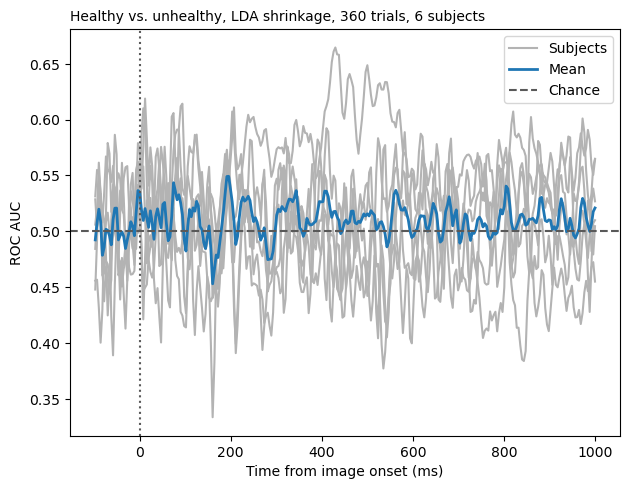

In [29]:
fig, ax = plot_curves(curves)
ax.set_title("Healthy vs. unhealthy, LDA shrinkage, 360 trials, 6 subjects", loc="left", fontsize=10)
fig.savefig("curves_healthy_LDA_6subjects.png", dpi=200)
plt.show()

**Result.** The mean curve stays between ≈ 0.48 and 0.55 over the whole epoch, with oscillations of the same size before and after image onset: no group-level effect. Individual peaks (max AUC per subject 0.59–0.66) are not above what noise produces. One subject (sub-006) reaches ≈ 0.65 around 400–450 ms.

## 7. Chance-level control (sub-006)

The same time-resolved decoding is repeated with labels shuffled **across images** (`chance_control`), 5 times: since labels no longer match the images, any decoding is pure chance. The grey curves show how high noise alone can go.

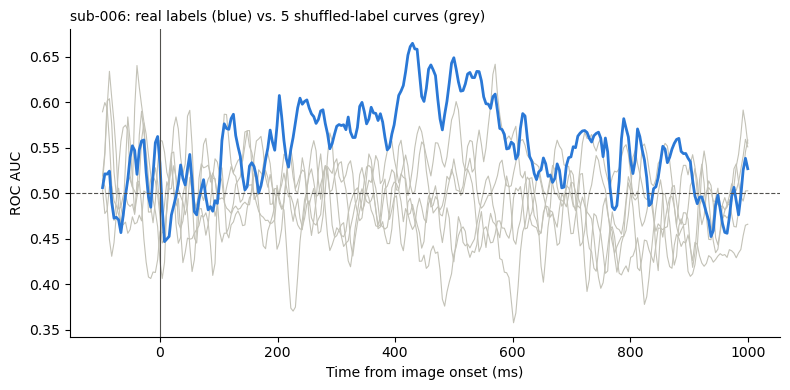

In [30]:
X, y, images = load_subject("sub-006")
real = curves_all.sel(subject="sub-006")
perm = chance_control(X, y, images, clf, n_permutations=5)   # 5 curves with shuffled labels

fig, ax = plt.subplots(figsize=(8, 4))
for p in perm:
    ax.plot(perm.time_ms, p, color="#c3c2b7", linewidth=0.8)
ax.plot(real.time_ms, real, color="#2a78d6", linewidth=2)
ax.axhline(0.5, color="#52514e", linewidth=0.8, linestyle="--")
ax.axvline(0, color="#52514e", linewidth=0.8)
ax.set_xlabel("Time from image onset (ms)")
ax.set_ylabel("ROC AUC")
ax.set_title("sub-006: real labels (blue) vs. 5 shuffled-label curves (grey)", loc="left", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig("chance_control_sub006.png", dpi=200)
plt.show()

**Result.** Before image onset the real curve (blue) stays within the shuffled curves (no leakage). Between ≈ 200 and 580 ms it is almost always above them, peaking at 0.66 around 430 ms, then falls back after ≈ 600 ms. sub-006 therefore shows a genuine healthy/unhealthy effect in the window reported by the paper (≈ 150–600 ms). With 5 permutations this is indicative only; a formal test needs ≥ 100 permutations (or a cluster test).

## 8. Conclusion

| Analysis | Trials | Mean AUC (6 subjects) | Conclusion |
|---|---|---|---|
| 8 classifiers, window 200–500 ms | 360 | 0.492–0.522 | all at chance, no method better than another |
| 8 classifiers + PCA | 360 | 0.485–0.502 | PCA does not help |
| LDA, time-resolved | 360 | ≈ 0.50 (0.48–0.55) | no group effect |
| Chance control, sub-006 | 360 | peak 0.66 at ≈ 430 ms | genuine effect in this subject (≈ 200–580 ms) |

**Take-away.** With 6 subjects, healthy vs. unhealthy is not decodable at the group level, whatever the classifier, the regularisation or PCA. The effect exists in some participants (sub-006) but varies a lot between people, which is why the paper needed ≈ 110 participants. **Next step:** run LDA with shrinkage (window 200–500 ms and time-resolved) on ≈ 30 subjects, loading one subject at a time, and test the group mean against chance.